# Video-First Discovery Feed: A/B Test Analysis
**Experiment:** EXP-PODVID-014 &nbsp;|&nbsp; **Author:** Amit Verma &nbsp;|&nbsp; **Date:** November 2026

**Business question.** Does a video-first discovery feed increase podcast listening, without hurting app stability or music listening?

**Design.** 2,000 users, 50/50 user-level randomization, 14 days (3 to 16 Mar 2025), intent-to-treat, two-sided alpha = 0.05.

**Hypotheses.** H0: mean daily podcast minutes per user is the same in Control and Treatment. H1: it differs.

**Contents:** 1 Audit and clean · 2 Validate the experiment · 3 Build the user-level table (SQL) · 4 Test results, guardrails, segments, power, novelty · Recommendation

In [1]:
import os, sqlite3
import numpy as np, pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

# ---- plot style -------------------------------------------------------
GREEN, GREY, RED, INK = "#1DB954", "#8A8A8A", "#E5484D", "#191414"
COL = {"Control": GREY, "Treatment": GREEN}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "axes.grid.axis": "y", "grid.alpha": .25, "font.size": 10,
                     "axes.titleweight": "bold", "axes.titlesize": 11.5})
def save(fig, name):
    os.makedirs("images", exist_ok=True)
    fig.savefig(f"images/{name}.png", dpi=160, bbox_inches="tight")

# ---- load data into an in-memory SQLite database ----------------------
users = pd.read_csv("data/users_experiment_map.csv")
act   = pd.read_csv("data/daily_user_activity.csv")
conn = sqlite3.connect(":memory:")
users.to_sql("users_experiment_map", conn, index=False)
act.to_sql("daily_user_activity", conn, index=False)
q = lambda sql: pd.read_sql(sql, conn)

print("users:", users.shape, "| activity:", act.shape)   # expect (2000, 5) and (19741, 6)

users: (2000, 5) | activity: (19741, 6)


## 1. Audit and clean the data

In [2]:
canonical = {"North America", "Europe", "LATAM", "APAC", "MEA"}
audit = pd.DataFrame([
    ("Exact duplicate activity rows",          int(act.duplicated().sum())),
    ("Orphan rows (User_ID not in user map)",  int((~act.User_ID.isin(users.User_ID)).sum())),
    ("Podcast minutes > 1,440 (24h) rows",     int((act.Podcast_Minutes_Listened > 1440).sum())),
    ("Null podcast minutes",                   int(act.Podcast_Minutes_Listened.isna().sum())),
    ("Users with non-standard Region label",   int((~users.Region.isin(canonical)).sum())),
    ("Null Account_Age_Days",                  int(users.Account_Age_Days.isna().sum())),
    ("Users with no activity rows",            int((~users.User_ID.isin(act.User_ID)).sum())),
], columns=["issue", "count"])
audit

,issue,count
0,Exact duplicate activity rows,78
1,Orphan rows (User_ID not in user map),20
2,"Podcast minutes > 1,440 (24h) rows",13
3,Null podcast minutes,158
4,Users with non-standard Region label,47
5,Null Account_Age_Days,30
6,Users with no activity rows,0


In [3]:
# Cleaning log: row counts must reconcile at every step
n0 = len(act)
a = act.drop_duplicates();                      n1 = len(a)
a = a[a.User_ID.isin(users.User_ID)];           n2 = len(a)
a = a[~(a.Podcast_Minutes_Listened > 1440)];    n3 = len(a)

pd.DataFrame({
    "step": ["Raw rows", "Drop exact duplicates", "Drop orphan IDs", "Drop podcast > 1,440 min"],
    "rows_removed": [0, n0-n1, n1-n2, n2-n3],
    "rows_remaining": [n0, n1, n2, n3]})

,step,rows_removed,rows_remaining
0,Raw rows,0,19741
1,Drop exact duplicates,78,19663
2,Drop orphan IDs,20,19643
3,"Drop podcast > 1,440 min",12,19631


**Cleaning decisions.** 110 of 19,741 activity rows were removed (0.6%). Duplicates were exact copies, orphan rows cannot be assigned to a variant, and a day cannot have more than 1,440 minutes. The 157 remaining null podcast-minute rows are kept: they add nothing to minute sums but still count as an active day. Region labels were standardized to five names, and 30 null `Account_Age_Days` are left as null. Every enrolled user has activity, so the zero-activity edge case does not occur here, but the LEFT JOIN in Step 3 would handle it.

## 2. Validate the experiment (before looking at any results)

In [4]:
users["Region"] = (users.Region.str.strip().str.title()
                   .replace({"Latam": "LATAM", "Apac": "APAC", "Mea": "MEA"}))

counts = users.Variant.value_counts()[["Control", "Treatment"]]
chi2, p_srm = stats.chisquare(counts.values)
p_region  = stats.chi2_contingency(pd.crosstab(users.Variant, users.Region))[1]
p_premium = stats.chi2_contingency(pd.crosstab(users.Variant, users.Premium_Status))[1]
c_age = users.loc[users.Variant == "Control", "Account_Age_Days"].dropna()
t_age = users.loc[users.Variant == "Treatment", "Account_Age_Days"].dropna()
p_age = stats.ttest_ind(t_age, c_age, equal_var=False).pvalue

pd.DataFrame({
    "check": ["Sample ratio (50/50)", "Premium status balance", "Account age balance", "Region balance"],
    "detail": [f"{counts['Control']:,} vs {counts['Treatment']:,}", "chi-square", f"{c_age.mean():.0f} vs {t_age.mean():.0f} days", "chi-square"],
    "p_value": [round(p_srm, 3), round(p_premium, 3), round(p_age, 3), round(p_region, 3)],
    "verdict": ["Pass (alarm if p < 0.001)", "Pass", "Pass", "Borderline, see note"]})

,check,detail,p_value,verdict
0,Sample ratio (50/50),"1,015 vs 985",0.502,Pass (alarm if p < 0.001)
1,Premium status balance,chi-square,0.947,Pass
2,Account age balance,845 vs 807 days,0.138,Pass
3,Region balance,chi-square,0.026,"Borderline, see note"


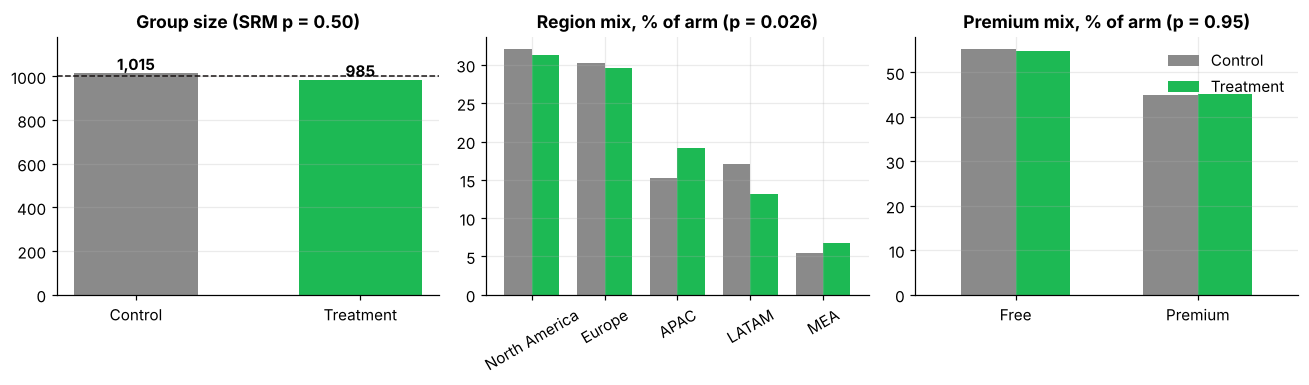

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.6))

ax[0].bar(counts.index, counts.values, color=[COL[v] for v in counts.index], width=.55)
ax[0].axhline(1000, ls="--", c=INK, lw=1); ax[0].set_ylim(0, 1180)
for i, v in enumerate(counts.values): ax[0].text(i, v + 15, f"{v:,}", ha="center", fontweight="bold")
ax[0].set_title(f"Group size (SRM p = {p_srm:.2f})")

order = ["North America", "Europe", "APAC", "LATAM", "MEA"]
rm = (pd.crosstab(users.Region, users.Variant, normalize="columns") * 100).reindex(order)
rm[["Control", "Treatment"]].plot.bar(ax=ax[1], color=[GREY, GREEN], rot=30, legend=False, width=.75)
ax[1].set_title(f"Region mix, % of arm (p = {p_region:.3f})"); ax[1].set_xlabel("")

pm = pd.crosstab(users.Premium_Status, users.Variant, normalize="columns") * 100
pm[["Control", "Treatment"]].plot.bar(ax=ax[2], color=[GREY, GREEN], rot=0, width=.6)
ax[2].set_title(f"Premium mix, % of arm (p = {p_premium:.2f})"); ax[2].set_xlabel(""); ax[2].legend(frameon=False)

plt.tight_layout(); save(fig, "randomization_checks"); plt.show()

**Verdict: randomization looks healthy.** No sample ratio mismatch (p = 0.50) and good balance on Premium and account age. Region is mildly uneven (p = 0.026). With four balance tests, one borderline p-value is plausible by chance, and Step 4d shows the result is unchanged after adjusting for Region.

## 3. Build the user-level table (SQL)
Daily rows are repeated measurements of the same person, so they are collapsed to **one row per user**. The LEFT JOIN starts from the users table so every enrolled user is kept and inactive days count as zero (intent-to-treat). The denominator is always 14 days.

In [6]:
base_sql = """
WITH clean_users AS (
  SELECT User_ID, Variant,
    CASE UPPER(TRIM(Region))
      WHEN 'NORTH AMERICA' THEN 'North America'
      WHEN 'EUROPE' THEN 'Europe'
      WHEN 'LATAM' THEN 'LATAM'
      WHEN 'APAC' THEN 'APAC'
      WHEN 'MEA' THEN 'MEA' END AS Region,
    Premium_Status, Account_Age_Days
  FROM users_experiment_map
),
deduped_activity AS (
  SELECT *, ROW_NUMBER() OVER (PARTITION BY User_ID, Date ORDER BY Date) AS rn
  FROM daily_user_activity
),
clean_activity AS (
  SELECT User_ID, Date,
    Podcast_Minutes_Listened AS podcast_min,
    Music_Minutes_Listened   AS music_min,
    Discovery_Feed_Clicks    AS clicks,
    App_Crashes              AS crashes
  FROM deduped_activity
  WHERE rn = 1
    AND (Podcast_Minutes_Listened IS NULL OR Podcast_Minutes_Listened <= 1440)
),
user_metrics AS (
  SELECT u.User_ID, u.Variant, u.Region, u.Premium_Status, u.Account_Age_Days,
    COALESCE(SUM(a.podcast_min),0)/14.0 AS avg_daily_podcast_min,
    COALESCE(SUM(a.music_min),0)/14.0   AS avg_daily_music_min,
    COALESCE(SUM(a.clicks),0)/14.0      AS avg_daily_clicks,
    COALESCE(SUM(a.crashes),0)/14.0     AS avg_daily_crashes,
    COUNT(a.Date)/14.0                  AS active_day_rate,
    COALESCE(SUM(CASE WHEN a.podcast_min > 0 THEN 1 ELSE 0 END),0) AS podcast_days
  FROM clean_users u
  LEFT JOIN clean_activity a ON u.User_ID = a.User_ID
  GROUP BY u.User_ID, u.Variant, u.Region, u.Premium_Status, u.Account_Age_Days
)
"""
user_metrics = q(base_sql + "SELECT * FROM user_metrics")
assert len(user_metrics) == 2000, "expected one row per enrolled user"
print(user_metrics.shape)
user_metrics.head()

(2000, 11)


,User_ID,Variant,Region,Premium_Status,Account_Age_Days,avg_daily_podcast_min,avg_daily_music_min,avg_daily_clicks,avg_daily_crashes,active_day_rate,podcast_days
0,U101107,Treatment,LATAM,Free,553.0,10.778571,46.935714,3.142857,0.0,0.785714,6
1,U101379,Control,APAC,Premium,713.0,6.285714,53.735714,1.428571,0.0,0.785714,8
2,U101492,Treatment,Europe,Free,977.0,39.514286,52.907143,0.642857,0.0,1.000000,12
3,U101493,Control,APAC,Free,1606.0,2.271429,49.507143,0.071429,0.0,0.571429,4
4,U102075,Treatment,North America,Premium,648.0,1.821429,51.721429,1.571429,0.0,0.571429,6


In [7]:
q(base_sql + """
SELECT Variant, COUNT(*) AS users,
  ROUND(AVG(avg_daily_podcast_min),2) AS podcast_min,
  ROUND(AVG(avg_daily_music_min),2)   AS music_min,
  ROUND(AVG(avg_daily_clicks),3)      AS clicks,
  ROUND(AVG(avg_daily_crashes),4)     AS crashes,
  ROUND(AVG(active_day_rate),3)       AS active_rate,
  ROUND(AVG(podcast_days),2)          AS podcast_days
FROM user_metrics GROUP BY Variant
""")

,Variant,users,podcast_min,music_min,clicks,crashes,active_rate,podcast_days
0,Control,1015,10.35,38.54,0.688,0.0161,0.695,6.72
1,Treatment,985,11.42,38.47,0.986,0.0191,0.707,6.99


## 4. Results
### 4a. Primary metric: average daily podcast minutes per user

In [8]:
def lift_stats(d, col, alt="two-sided"):
    c = d.loc[d.Variant == "Control", col]; t = d.loc[d.Variant == "Treatment", col]
    r = stats.ttest_ind(t, c, equal_var=False, alternative=alt)     # Welch t-test
    diff = t.mean() - c.mean()
    se = np.sqrt(t.var(ddof=1)/len(t) + c.var(ddof=1)/len(c))
    return dict(n_ctrl=len(c), n_trt=len(t), ctrl=float(c.mean()), trt=float(t.mean()),
                diff=float(diff), rel=float(diff/c.mean()),
                lo=float(diff - 1.96*se), hi=float(diff + 1.96*se), p=float(r.pvalue))

def welch(col, alt="two-sided"):
    return lift_stats(user_metrics, col, alt)

def tidy(results, dec=3):
    df = pd.DataFrame(results).T.astype(float)
    return pd.DataFrame({
        "control": df.ctrl.round(dec), "treatment": df.trt.round(dec), "diff": df["diff"].round(dec),
        "lift": (df.rel*100).round(1).astype(str) + "%",
        "95% CI (diff)": [f"[{l:.3f}, {h:.3f}]" for l, h in zip(df.lo, df.hi)],
        "p-value": ["<0.0001" if p < 1e-4 else f"{p:.4f}" for p in df.p]})

c = user_metrics.loc[user_metrics.Variant == "Control", "avg_daily_podcast_min"]
t = user_metrics.loc[user_metrics.Variant == "Treatment", "avg_daily_podcast_min"]
primary = welch("avg_daily_podcast_min")
d_cohen = (t.mean() - c.mean()) / np.sqrt((t.var(ddof=1) + c.var(ddof=1)) / 2)
print(f"Cohen's d = {d_cohen:.3f} (small effect, typical for product tests)")
tidy({"Podcast min / user / day": primary})

Cohen's d = 0.109 (small effect, typical for product tests)


,control,treatment,diff,lift,95% CI (diff),p-value
Podcast min / user / day,10.348,11.424,1.075,10.4%,"[0.211, 1.940]",0.0149


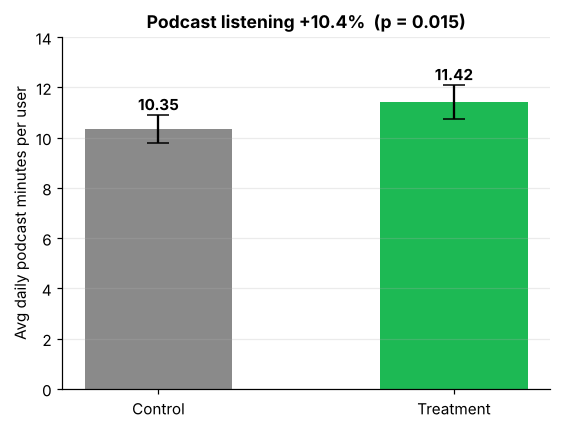

In [9]:
fig, ax = plt.subplots(figsize=(5.2, 4))
means = [c.mean(), t.mean()]; err = [1.96*c.sem(), 1.96*t.sem()]
ax.bar(["Control", "Treatment"], means, yerr=err, capsize=7, color=[GREY, GREEN], width=.5, error_kw={"lw": 1.5})
for i, (m, e) in enumerate(zip(means, err)): ax.text(i, m + e + .2, f"{m:.2f}", ha="center", fontweight="bold")
ax.set_ylim(0, 14); ax.set_ylabel("Avg daily podcast minutes per user")
ax.set_title(f"Podcast listening {primary['rel']:+.1%}  (p = {primary['p']:.3f})")
plt.tight_layout(); save(fig, "primary_result"); plt.show()

**Result:** +1.08 min/day (+10.4%), 95% CI [0.21, 1.94], p = 0.015. The interval excludes zero, so H0 is rejected at the 5% level.

In [10]:
# Robustness: a rank-based test and a bootstrap CI
print("Mann-Whitney p:", round(stats.mannwhitneyu(t, c).pvalue, 4))
rng = np.random.default_rng(42)
bs = [rng.choice(t, len(t)).mean() - rng.choice(c, len(c)).mean() for _ in range(5000)]
print("Bootstrap 95% CI:", np.round(np.percentile(bs, [2.5, 97.5]), 3))

Mann-Whitney p: 0.0577
Bootstrap 95% CI: [0.235 1.911]


The bootstrap CI agrees with the t-test. Mann-Whitney (p = 0.058) just misses 0.05. It compares whole distributions rather than means, but it signals the result is **fragile rather than overwhelming**.

### 4b. Secondary metrics (Bonferroni-corrected alpha = 0.05 / 4 = 0.0125)

In [11]:
sec = tidy({"Discovery feed clicks / day": welch("avg_daily_clicks"),
            "Podcast listening days (of 14)": welch("podcast_days"),
            "Active-day rate": welch("active_day_rate")})
sec["significant at 0.0125"] = ["Yes" if (p == "<0.0001" or float(p) < 0.0125) else "No" for p in sec["p-value"]]
user_metrics["listener"] = (user_metrics.podcast_days > 0).astype(int)
print("Podcast listener rate:", user_metrics.groupby("Variant").listener.mean().round(4).to_dict(), "(ceiling effect)")
sec

Podcast listener rate: {'Control': 0.997, 'Treatment': 0.9959} (ceiling effect)


,control,treatment,diff,lift,95% CI (diff),p-value,significant at 0.0125
Discovery feed clicks / day,0.688,0.986,0.298,43.3%,"[0.237, 0.359]",<0.0001,Yes
Podcast listening days (of 14),6.722,6.994,0.272,4.0%,"[0.068, 0.475]",0.0090,Yes
Active-day rate,0.695,0.707,0.012,1.8%,"[-0.004, 0.029]",0.1339,No


The mechanism chain holds: **more feed clicks, then more listening days, then more minutes.** Active-day rate is not significant. Listener rate is about 99.7% in both arms, so there is no reach story.

### 4c. Guardrails (one-sided tests for harm)

In [12]:
g = {"Crashes per user-day":  welch("avg_daily_crashes", "greater"),
     "Music minutes / day":   welch("avg_daily_music_min", "less"),
     "Active-day rate":       welch("active_day_rate", "less")}
rules = {"Crashes per user-day": ("rise > 10% or significant", lambda r: r["rel"] > .10 or r["p"] < .05),
         "Music minutes / day":  ("drop > 3% or significant", lambda r: r["rel"] < -.03 or r["p"] < .05),
         "Active-day rate":      ("significant drop",         lambda r: r["p"] < .05)}
guard = tidy(g, 4)
guard.insert(0, "breach rule", [rules[k][0] for k in g])
guard["status"] = ["BREACHED" if rules[k][1](g[k]) else "pass" for k in g]
guard.loc["Premium cancellations"] = ["cancellation rate up", "", "", "", "", "", "not measurable", "OPEN"]
guard

,breach rule,control,treatment,diff,lift,95% CI (diff),p-value,status
Crashes per user-day,rise > 10% or significant,0.0161,0.0191,0.003,18.8%,"[-0.000, 0.006]",0.0318,BREACHED
Music minutes / day,drop > 3% or significant,38.5425,38.4733,-0.0692,-0.2%,"[-1.488, 1.349]",0.4619,pass
Active-day rate,significant drop,0.695,0.7074,0.0124,1.8%,"[-0.004, 0.029]",0.9330,pass
Premium cancellations,cancellation rate up,,,,,,not measurable,OPEN


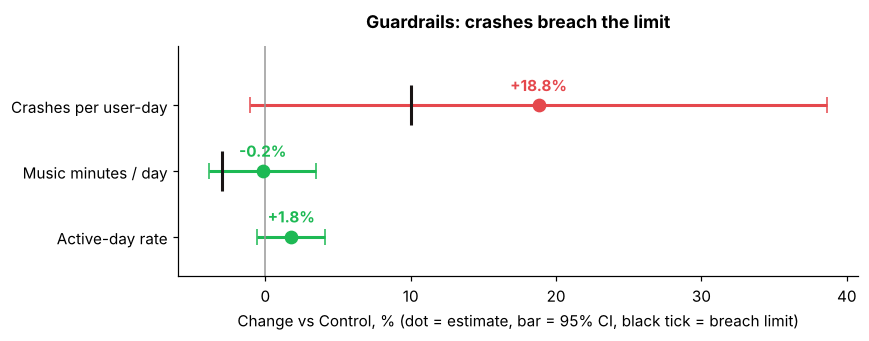

In [13]:
fig, ax = plt.subplots(figsize=(8, 3.2))
names = list(g)[::-1]; limits = {"Crashes per user-day": .10, "Music minutes / day": -.03, "Active-day rate": None}
for i, k in enumerate(names):
    r = g[k]; ok = not rules[k][1](r); col = GREEN if ok else RED
    lo, hi, m = r["lo"]/r["ctrl"], r["hi"]/r["ctrl"], r["rel"]
    ax.errorbar(m*100, i, xerr=[[ (m-lo)*100 ], [ (hi-m)*100 ]], fmt="o", color=col, capsize=5, lw=2, ms=8)
    ax.text(m*100, i + .22, f"{m:+.1%}", ha="center", color=col, fontweight="bold")
    if limits[k] is not None: ax.plot(limits[k]*100, i, marker="|", ms=26, color=INK, mew=2)
ax.axvline(0, color="#999", lw=1); ax.set_ylim(-.6, len(names)-.1)
ax.set_yticks(range(len(names))); ax.set_yticklabels(names); ax.grid(axis="y", alpha=0)
ax.set_xlabel("Change vs Control, % (dot = estimate, bar = 95% CI, black tick = breach limit)")
ax.set_title("Guardrails: crashes breach the limit", pad=12)
plt.tight_layout(); save(fig, "guardrails"); plt.show()

**Crashes are breached on both rules:** +18.8% (above the 10% limit) and significant (one-sided p = 0.032). Crashes are rare events (about 0.016 per user-day), so the interval is wide (roughly -1% to +39%) and the exact size of the increase is uncertain, but the evidence points the wrong way. Music is flat (-0.2%), so podcast growth is incremental, not cannibalizing, although the CI cannot fully rule out a small decline. **Premium cancellation cannot be evaluated**: neither table has a cancellation event, so it needs a billing-table join in production.

### 4d. Segments (exploratory) and region-adjusted check

In [14]:
rows = [("Overall", "All users", user_metrics)]
for seg in ["Premium_Status", "Region"]:
    for val, d in user_metrics.groupby(seg): rows.append((seg, val, d))
seg = pd.DataFrame([{"segment": s, "value": v, **lift_stats(d, "avg_daily_podcast_min")} for s, v, d in rows])
seg_view = pd.DataFrame({"segment": seg.segment, "value": seg.value, "n_ctrl": seg.n_ctrl, "n_trt": seg.n_trt,
                         "diff_min": seg["diff"].round(2), "lift": (seg.rel*100).round(1).astype(str) + "%",
                         "p-value": seg.p.round(3)})
seg_view

,segment,value,n_ctrl,n_trt,diff_min,lift,p-value
0,Overall,All users,1015,985,1.08,10.4%,0.015
1,Premium_Status,Free,560,541,0.85,8.2%,0.144
2,Premium_Status,Premium,455,444,1.36,13.0%,0.047
3,Region,APAC,155,189,0.57,5.4%,0.577
4,Region,Europe,307,291,1.33,12.8%,0.107
5,Region,LATAM,173,130,2.39,24.8%,0.035
6,Region,MEA,55,67,-0.87,-8.2%,0.598
7,Region,North America,325,308,0.87,8.3%,0.280


In [15]:
# Treatment effect adjusted for Region and Premium (OLS, HC3 robust SE, numpy only)
X = pd.get_dummies(user_metrics[["Variant", "Region", "Premium_Status"]], drop_first=True).astype(float)
X.insert(0, "const", 1.0)
cols = ["const", "Variant_Treatment"] + [k for k in X.columns if k not in ("const", "Variant_Treatment")]
Xv, y = X[cols].values, user_metrics.avg_daily_podcast_min.values
XtXi = np.linalg.inv(Xv.T @ Xv); b = XtXi @ Xv.T @ y
res = y - Xv @ b; h = np.einsum("ij,jk,ik->i", Xv, XtXi, Xv)
Z = Xv * (res / (1 - h))[:, None]; V = XtXi @ (Z.T @ Z) @ XtXi
se = np.sqrt(np.diag(V))[1]
print(f"Adjusted effect: {b[1]:+.3f} min  95% CI [{b[1]-1.96*se:.2f}, {b[1]+1.96*se:.2f}]  "
      f"p = {2*(1-stats.norm.cdf(abs(b[1]/se))):.4f}")

Adjusted effect: +1.080 min  95% CI [0.21, 1.95]  p = 0.0151


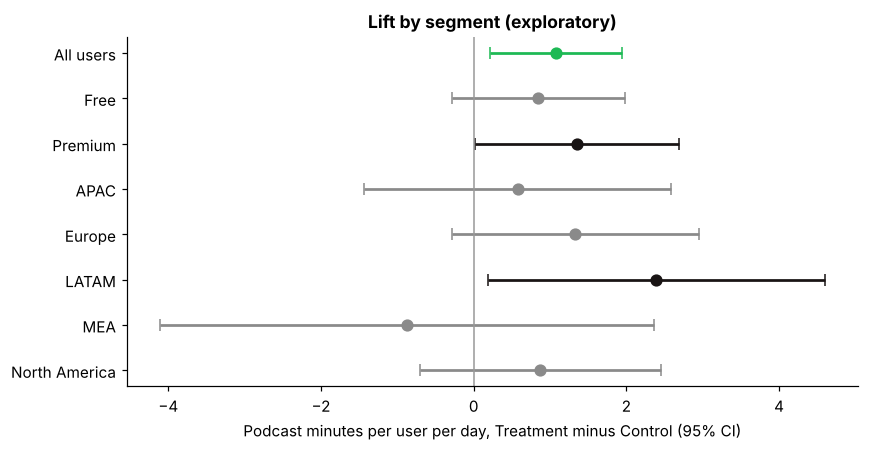

In [16]:
fig, ax = plt.subplots(figsize=(8, 4.2))
s = seg.iloc[::-1].reset_index(drop=True)
for i, r in s.iterrows():
    sig = (r.lo > 0) or (r.hi < 0)
    col = GREEN if (r.value == "All users") else (INK if sig else GREY)
    ax.errorbar(r["diff"], i, xerr=[[r["diff"]-r.lo], [r.hi-r["diff"]]], fmt="o", color=col, capsize=4, lw=1.8, ms=7)
ax.axvline(0, color="#999", lw=1)
ax.set_yticks(range(len(s))); ax.set_yticklabels(s.value); ax.grid(axis="y", alpha=0)
ax.set_xlabel("Podcast minutes per user per day, Treatment minus Control (95% CI)")
ax.set_title("Lift by segment (exploratory)")
plt.tight_layout(); save(fig, "segment_forest"); plt.show()

Premium (+13.0%, p = 0.047) and LATAM (+24.8%, p = 0.035) look strong, while MEA is negative (-8.2%, p = 0.60). With 7 cuts, none survive multiple-testing correction, so treat these as **hypotheses for a follow-up test, not findings**. The adjusted effect (+1.08, p = 0.015) matches the unadjusted one, so the Region imbalance is not driving the result.

### 4e. Power and minimum detectable effect

In [17]:
sd = c.std(ddof=1)
n1, n2 = len(c), len(t)
mde_d = (stats.norm.ppf(0.975) + stats.norm.ppf(0.80)) * np.sqrt(1/n1 + 1/n2)
print(f"Control SD = {sd:.2f} min | MDE = {mde_d*sd:.2f} min ({mde_d*sd/c.mean():.1%}) at 80% power | observed lift = {t.mean()-c.mean():.2f} min")

Control SD = 8.93 min | MDE = 1.12 min (10.8%) at 80% power | observed lift = 1.08 min


The test could reliably detect only about a 10.8% lift, and the observed lift (10.4%) sits right at that threshold. A result that barely clears the bar is usually **overstated** (winner's curse), so the true effect is probably smaller.

### 4f. Novelty effect

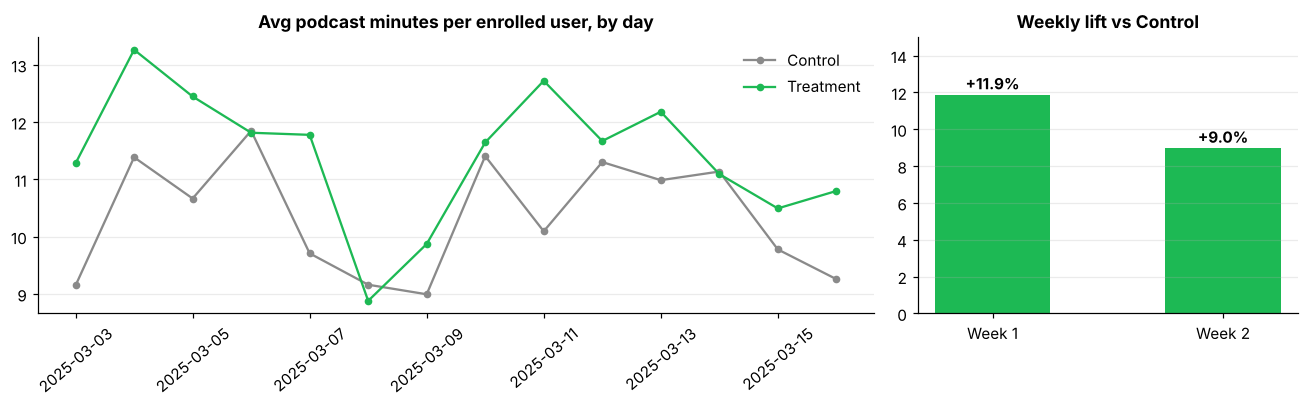

In [18]:
a2 = act.drop_duplicates()
a2 = a2[a2.User_ID.isin(users.User_ID)]
a2 = a2[~(a2.Podcast_Minutes_Listened > 1440)].merge(users[["User_ID", "Variant"]], on="User_ID")
n = users.Variant.value_counts()
daily = a2.groupby(["Date", "Variant"]).Podcast_Minutes_Listened.sum().unstack() / n
a2["week"] = (pd.to_datetime(a2.Date) - pd.Timestamp("2025-03-03")).dt.days // 7
wk = a2.groupby(["week", "Variant"]).Podcast_Minutes_Listened.sum().unstack() / n / 7
wk_lift = (wk.Treatment / wk.Control - 1) * 100

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [2.2, 1]})
for v in ["Control", "Treatment"]: ax[0].plot(pd.to_datetime(daily.index), daily[v], marker="o", ms=4, color=COL[v], label=v)
ax[0].set_title("Avg podcast minutes per enrolled user, by day"); ax[0].legend(frameon=False)
ax[0].tick_params(axis="x", rotation=40)
ax[1].bar(["Week 1", "Week 2"], wk_lift.values, color=GREEN, width=.5)
for i, v in enumerate(wk_lift.values): ax[1].text(i, v + .3, f"{v:+.1f}%", ha="center", fontweight="bold")
ax[1].set_ylim(0, 15); ax[1].set_title("Weekly lift vs Control")
plt.tight_layout(); save(fig, "novelty_trend"); plt.show()

Daily lines are noisy, but the weekly lift fades from about +11.9% in week 1 to +9.0% in week 2. That is a mild sign of a novelty effect, so the re-test should run at least three weeks.

## Recommendation: ITERATE (do not ship to 100% yet)

| Question | Answer |
|---|---|
| Does it improve podcast listening? | **Yes**: +10.4% (95% CI +0.21 to +1.94 min/day, p = 0.015) |
| Is the mechanism visible? | **Yes**: feed clicks +43%, listening days +4% |
| Is the experiment trustworthy? | **Yes**: no SRM, balanced on Premium and age, Region imbalance not driving the result |
| Is the app still stable? | **No**: crashes +18.8%, above the 10% limit and significant |
| Is music protected? | **Yes**: -0.2%, no cannibalization |

**Caveats.** (1) Premium cancellation could not be evaluated. (2) The result is fragile (Mann-Whitney p = 0.058) and likely overstated. (3) The lift fades from week 1 to week 2. (4) Segment findings are exploratory. (5) The test was powered for about a 10% lift only.

**Next steps.** Fix the crash cause, then re-test with a larger sample and at least three weeks. Add cancellation data. Investigate MEA before any regional rollout.